# Point Transformer V2 for Power Line Segmentation

This notebook contains the complete pipeline for training a Point Transformer V2 model on LiDAR point cloud data.

**Classes:**
- Class 0: High Vegetation
- Class 1: Power Lines
- Class 2: Pylons
- Class 3: Others

## 1. Configuration - All Tunable Parameters

In [1]:
# ============================================================================
# GLOBAL CONFIGURATION - MODIFY THESE PARAMETERS TO TUNE THE MODEL
# ============================================================================

# Training Continuation
CONTINUE_TRAINING = True  # Set to True to resume from checkpoint
RESUME_CHECKPOINT = 'checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt'  # Path to checkpoint to resume from

# Data Configuration
DATA_DIR = '../data/processed_data_optimized'
MAX_TRAIN_SAMPLES = None  # Set to None for all data, or integer to limit (e.g., 27259 for half)
MAX_TEST_SAMPLES = None   # Set to None for all data, or integer to limit

# Model Architecture
NUM_CLASSES = 4           # Number of semantic classes
D_MODEL = 156             # Model dimension (128 for MPS, 256 for CUDA)
NUM_LAYERS = 3            # Number of transformer layers (2 for MPS, 4 for CUDA)
NUM_HEADS = 8             # Number of attention heads
K_NEIGHBORS = 16          # Number of nearest neighbors for attention

# Training Hyperparameters
BATCH_SIZE = 2            # Batch size (2 for MPS, 8 for CUDA)
MAX_EPOCHS = 10          # Maximum training epochs
LEARNING_RATE = 1e-3      # Initial learning rate
WEIGHT_DECAY = 1e-4       # L2 regularization
GRADIENT_CLIP = 1.0       # Gradient clipping value
DROPOUT = 0.3             # Dropout rate in segmentation head

# Data Processing
NUM_POINTS = 4096         # Number of points per sample
USE_FPS = True            # Use Farthest Point Sampling (True recommended)
NUM_WORKERS = 0           # DataLoader workers (0 for MPS, 4+ for CUDA)

# Class Weights (for imbalanced data)
# Set to None to calculate from data, or provide custom weights
# Format: [High Vegetation, Power Lines, Pylons, Others]
CLASS_WEIGHTS = None      # None = auto-calculate, or e.g., [1.0, 5.0, 10.0, 1.0]

# Callbacks and Monitoring
EARLY_STOPPING_PATIENCE = 20    # Epochs to wait before early stopping
SAVE_TOP_K = 3                  # Number of best checkpoints to keep
CHECKPOINT_MONITOR = 'val_miou' # Metric to monitor ('val_miou' or 'val_loss')
LOG_EVERY_N_STEPS = 10          # Log frequency

# Output Directories
CHECKPOINT_DIR = 'checkpoints'
TENSORBOARD_DIR = 'lightning_logs'
PREDICTION_DIR = 'predictions'

# Visualization
NUM_VISUALIZATION_SAMPLES = 5   # Number of samples to visualize
VISUALIZATION_DPI = 150         # DPI for saved figures

# Class Information
CLASS_NAMES = ['High Vegetation', 'Power Lines', 'Pylons', 'Others']
CLASS_COLORS = ['darkgreen', 'orange', 'blue', 'gray']

# ============================================================================
# END OF CONFIGURATION
# ============================================================================

print("Configuration loaded!")
print(f"Data directory: {DATA_DIR}")
print(f"Model: {NUM_LAYERS} layers, {D_MODEL} dimensions")
print(f"Training: {BATCH_SIZE} batch size, {MAX_EPOCHS} max epochs")
print(f"Points per sample: {NUM_POINTS}")

if CONTINUE_TRAINING:
    print(f"\nCONTINUE TRAINING MODE: Will resume from {RESUME_CHECKPOINT}")
else:
    print(f"\nNEW TRAINING MODE: Starting from scratch")

Configuration loaded!
Data directory: ../data/processed_data_optimized
Model: 3 layers, 156 dimensions
Training: 2 batch size, 10 max epochs
Points per sample: 4096

CONTINUE TRAINING MODE: Will resume from checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt


## 2. Imports

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

import lightning as L
from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from lightning.pytorch.loggers import TensorBoardLogger

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json
from tqdm import tqdm

import warnings
warnings.filterwarnings('ignore', '.*num_workers.*')
warnings.filterwarnings('ignore', '.*pin_memory.*')

print(f"PyTorch version: {torch.__version__}")
print(f"Lightning version: {L.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"MPS available: {torch.backends.mps.is_available()}")

PyTorch version: 2.7.1
Lightning version: 2.5.0.post0
CUDA available: False
MPS available: True


## 3. Dataset Classes

In [3]:
class PowerLineDataset(Dataset):
    """Dataset for power line point cloud segmentation"""

    def __init__(self, data_dir, split='train', num_points=4096, use_fps=True, max_samples=None):
        self.data_dir = Path(data_dir) / split
        self.num_points = num_points
        self.use_fps = use_fps
        self.split = split
        self.max_samples = max_samples

        # Get all sample files
        self.samples = sorted(list(self.data_dir.glob('*.pt')))
        
        if self.max_samples is not None:
            self.samples = self.samples[:self.max_samples]

        if not self.samples:
            raise ValueError(f"No samples found in {self.data_dir}")

        print(f"Loaded {len(self.samples)} samples from {split} split")

        # Load metadata
        metadata_path = Path(data_dir) / 'metadata.json'
        if metadata_path.exists():
            with open(metadata_path) as f:
                self.metadata = json.load(f)
                print(f"Metadata: {self.metadata['n_classes']} classes")
        else:
            self.metadata = {'n_classes': 4}

    def farthest_point_sampling(self, points, num_samples):
        """Farthest Point Sampling (FPS)"""
        N, D = points.shape
        if N <= num_samples:
            return np.arange(N)

        centroids = np.zeros(num_samples, dtype=np.int32)
        distance = np.ones(N) * 1e10
        farthest = np.random.randint(0, N)

        for i in range(num_samples):
            centroids[i] = farthest
            centroid = points[farthest, :]
            dist = np.sum((points - centroid) ** 2, axis=1)
            mask = dist < distance
            distance[mask] = dist[mask]
            farthest = np.argmax(distance)

        return centroids

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = torch.load(self.samples[idx], weights_only=False)
        points = sample['input_pcd']
        labels = sample['semantic_labels']
        
        # Ensure labels is always 1D - flatten but keep at least 1 dimension
        labels = labels.reshape(-1)
        
        # Convert to 0-indexed
        labels = labels - 1

        n_points = points.shape[0]

        if n_points > self.num_points:
            if self.use_fps:
                fps_idx = self.farthest_point_sampling(points.numpy(), self.num_points)
                points = points[fps_idx]
                labels = labels[fps_idx]
            else:
                choice = np.random.choice(n_points, self.num_points, replace=False)
                points = points[choice]
                labels = labels[choice]
        elif n_points < self.num_points:
            choice = np.random.choice(n_points, self.num_points - n_points, replace=True)
            extra_points = points[choice]
            extra_labels = labels[choice]
            points = torch.cat([points, extra_points], dim=0)
            labels = torch.cat([labels, extra_labels], dim=0)

        return {'points': points, 'labels': labels, 'idx': idx}


class PowerLineDataModule(L.LightningDataModule):
    """Lightning DataModule for power line segmentation"""

    def __init__(self, data_dir, batch_size=8, num_points=4096, num_workers=0, use_fps=True, max_samples=None):
        super().__init__()
        self.data_dir = data_dir
        self.batch_size = batch_size
        self.num_points = num_points
        self.num_workers = num_workers
        self.use_fps = use_fps
        self.max_samples = max_samples

    def setup(self, stage=None):
        if stage == 'fit' or stage is None:
            self.train_dataset = PowerLineDataset(self.data_dir, split='train', num_points=self.num_points, use_fps=self.use_fps, max_samples=self.max_samples)
            self.val_dataset = PowerLineDataset(self.data_dir, split='test', num_points=self.num_points, use_fps=False, max_samples=self.max_samples)

        if stage == 'test' or stage is None:
            self.test_dataset = PowerLineDataset(self.data_dir, split='test', num_points=self.num_points, use_fps=False, max_samples=self.max_samples)

    def train_dataloader(self):
        return DataLoader(self.train_dataset, batch_size=self.batch_size, shuffle=True, num_workers=self.num_workers, pin_memory=False, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_dataset, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers, pin_memory=False)

    def test_dataloader(self):
        return DataLoader(self.test_dataset, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers, pin_memory=False)


print("Dataset classes defined!")

Dataset classes defined!


## 4. Utility Functions

In [4]:
def get_device_info():
    """Check available device and return appropriate settings"""
    if torch.cuda.is_available():
        device = "cuda"
        accelerator = "gpu"
        devices = 1
        print(f"Using CUDA GPU: {torch.cuda.get_device_name(0)}")
    elif torch.backends.mps.is_available():
        device = "mps"
        accelerator = "mps"
        devices = 1
        print("Using Apple Silicon MPS")
    else:
        device = "cpu"
        accelerator = "cpu"
        devices = 1
        print("Using CPU")
    return device, accelerator, devices


def calculate_class_weights(data_dir):
    """Calculate class weights based on dataset statistics"""
    print("Calculating class weights from training data...")
    dataset = PowerLineDataset(data_dir, split='train', use_fps=False)

    class_counts = torch.zeros(4)
    sample_size = min(len(dataset), 100)
    print(f"Sampling {sample_size} chunks to estimate class distribution...")

    for i in tqdm(range(sample_size)):
        sample = dataset[i]
        labels = sample['labels']
        for cls in range(4):
            class_counts[cls] += (labels == cls).sum()

    total = class_counts.sum()
    class_weights = total / (class_counts + 1e-6)
    class_weights = class_weights / class_weights.sum() * 4

    print("\nClass distribution:")
    for i, (name, count, weight) in enumerate(zip(CLASS_NAMES, class_counts, class_weights)):
        percentage = 100 * count / total
        print(f"  {name}: {int(count):,} points ({percentage:.2f}%) -> weight: {weight:.3f}")

    return class_weights.tolist()


device, accelerator, devices = get_device_info()
print("Utility functions defined!")

Using Apple Silicon MPS
Utility functions defined!


## 5. Model Classes

In [5]:
def knn(x, k):
    """Find k nearest neighbors"""
    inner = -2 * torch.matmul(x.transpose(2, 1), x)
    xx = torch.sum(x**2, dim=1, keepdim=True)
    pairwise_distance = -xx - inner - xx.transpose(2, 1)
    idx = pairwise_distance.topk(k=k, dim=-1)[1]
    return idx


class TransformerBlock(nn.Module):
    """Point Transformer Block"""
    def __init__(self, d_model, num_heads=8, k=16):
        super().__init__()
        self.d_model = d_model
        self.k = k
        self.q = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v = nn.Linear(d_model, d_model)
        self.pos_mlp = nn.Sequential(nn.Linear(3, d_model), nn.ReLU(), nn.Linear(d_model, d_model))
        self.ffn = nn.Sequential(nn.Linear(d_model, d_model * 4), nn.ReLU(), nn.Linear(d_model * 4, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, features, positions, k=None):
        if k is None:
            k = self.k
        
        B, N, C = features.shape
        
        # KNN
        idx = knn(positions.transpose(1, 2), k)  # (B, N, k)
        
        # Gather neighbor features - use a safer indexing method
        idx_base = torch.arange(0, B, device=features.device).view(-1, 1, 1) * N
        idx_expanded = (idx + idx_base).view(B * N * k)
        
        features_flat = features.view(B * N, C)
        neighbor_features = features_flat[idx_expanded].view(B, N, k, C)
        
        positions_flat = positions.view(B * N, 3)
        neighbor_positions = positions_flat[idx_expanded].view(B, N, k, 3)
        
        # Relative positions
        relative_pos = positions.unsqueeze(2) - neighbor_positions
        pos_encoding = self.pos_mlp(relative_pos)
        
        # Attention
        q = self.q(features).unsqueeze(2)  # (B, N, 1, C)
        k_feat = self.k_linear(neighbor_features) + pos_encoding  # (B, N, k, C)
        v = self.v(neighbor_features) + pos_encoding  # (B, N, k, C)
        
        attn = torch.matmul(q, k_feat.transpose(-2, -1)) / (C ** 0.5)  # (B, N, 1, k)
        attn = F.softmax(attn, dim=-1)
        out = torch.matmul(attn, v).squeeze(2)  # (B, N, C)
        
        # Residual connections
        features = self.norm1(features + out)
        out = self.ffn(features)
        features = self.norm2(features + out)
        return features


class PointTransformerV2(nn.Module):
    """Point Transformer V2 for semantic segmentation"""
    def __init__(self, num_classes=4, d_model=256, num_layers=4, k=16):
        super().__init__()
        self.num_classes = num_classes
        self.input_embed = nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, k=k) for _ in range(num_layers)])
        self.seg_head = nn.Sequential(
            nn.Linear(d_model, 256), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(128, num_classes)
        )

    def forward(self, points):
        features = self.input_embed(points)
        for block in self.blocks:
            features = block(features, points)
        logits = self.seg_head(features)
        return logits


class PointTransformerLightning(L.LightningModule):
    """Lightning module for Point Transformer training"""
    def __init__(self, num_classes=4, d_model=256, num_layers=4, k=16, lr=1e-3, weight_decay=1e-4, class_weights=None, max_epochs=200):
        super().__init__()
        self.save_hyperparameters()
        self.model = PointTransformerV2(num_classes=num_classes, d_model=d_model, num_layers=num_layers, k=k)
        
        if class_weights is not None:
            # Ensure weights are valid (not too small)
            class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)
            # Replace near-zero weights with 1.0
            class_weights_tensor = torch.where(class_weights_tensor < 0.01, torch.ones_like(class_weights_tensor), class_weights_tensor)
            self.class_weights = class_weights_tensor
        else:
            self.class_weights = torch.ones(num_classes)
        
        self.criterion = nn.CrossEntropyLoss(weight=self.class_weights, ignore_index=-1)

    def forward(self, points):
        return self.model(points)

    def calculate_iou(self, pred, target, num_classes):
        ious = []
        pred = pred.view(-1)
        target = target.view(-1)
        for cls in range(num_classes):
            pred_inds = pred == cls
            target_inds = target == cls
            intersection = (pred_inds & target_inds).sum().float()
            union = (pred_inds | target_inds).sum().float()
            ious.append((intersection / union).item() if union > 0 else float('nan'))
        return ious

    def training_step(self, batch, batch_idx):
        points, labels = batch['points'], batch['labels']
        logits = self(points)
        loss = self.criterion(logits.reshape(-1, self.hparams.num_classes), labels.reshape(-1))
        acc = (logits.argmax(dim=-1) == labels).float().mean()
        self.log('train_loss', loss, prog_bar=True)
        self.log('train_acc', acc, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        points, labels = batch['points'], batch['labels']
        logits = self(points)
        loss = self.criterion(logits.reshape(-1, self.hparams.num_classes), labels.reshape(-1))
        pred = logits.argmax(dim=-1)
        acc = (pred == labels).float().mean()
        ious = self.calculate_iou(pred, labels, self.hparams.num_classes)
        mean_iou = np.nanmean([iou for iou in ious if not np.isnan(iou)])
        self.log('val_loss', loss, prog_bar=True)
        self.log('val_acc', acc, prog_bar=True)
        self.log('val_miou', mean_iou, prog_bar=True)
        return {'val_loss': loss, 'val_miou': mean_iou}

    def test_step(self, batch, batch_idx):
        return self.validation_step(batch, batch_idx)

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.weight_decay)
        scheduler = CosineAnnealingLR(optimizer, T_max=self.hparams.max_epochs, eta_min=1e-6)
        return {'optimizer': optimizer, 'lr_scheduler': {'scheduler': scheduler, 'interval': 'epoch'}}


print("Model classes defined!")

Model classes defined!


## 6. Calculate Class Weights

In [6]:
if CLASS_WEIGHTS is None:
    class_weights = calculate_class_weights(DATA_DIR)
    print(f"\nCalculated class weights: {class_weights}")
else:
    class_weights = CLASS_WEIGHTS
    print(f"\nUsing provided class weights: {class_weights}")

Calculating class weights from training data...
Loaded 24808 samples from train split
Metadata: 4 classes
Sampling 100 chunks to estimate class distribution...


100%|██████████| 100/100 [00:00<00:00, 1052.68it/s]


Class distribution:
  High Vegetation: 279,545 points (68.25%) -> weight: 0.000
  Power Lines: 0 points (0.00%) -> weight: 2.000
  Pylons: 0 points (0.00%) -> weight: 2.000
  Others: 130,055 points (31.75%) -> weight: 0.000

Calculated class weights: [7.15448360277815e-12, 2.0, 2.0, 1.5378108508823374e-11]


## 7. Setup Data and Model

In [7]:
# Create checkpoint directory
Path(CHECKPOINT_DIR).mkdir(exist_ok=True)

# Data module
print("Setting up data...")
dm = PowerLineDataModule(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    num_points=NUM_POINTS,
    num_workers=NUM_WORKERS,
    use_fps=USE_FPS,
    max_samples=MAX_TRAIN_SAMPLES
)

# Model initialization
print("Initializing model...")

if CONTINUE_TRAINING:
    # Load model from checkpoint
    checkpoint_path = Path(RESUME_CHECKPOINT)
    
    if not checkpoint_path.exists():
        print(f"\nERROR: Checkpoint not found at {checkpoint_path}")
        print("Available checkpoints:")
        for ckpt in sorted(Path(CHECKPOINT_DIR).glob('*.ckpt')):
            print(f"  - {ckpt}")
        raise FileNotFoundError(f"Checkpoint {checkpoint_path} does not exist")
    
    print(f"\nLoading checkpoint from {checkpoint_path}...")
    model = PointTransformerLightning.load_from_checkpoint(
        str(checkpoint_path),
        # Override parameters if needed
        max_epochs=MAX_EPOCHS,  # Update to new max_epochs
        lr=LEARNING_RATE,  # Can override learning rate
        weight_decay=WEIGHT_DECAY
    )
    
    # Get info from loaded checkpoint
    checkpoint_data = torch.load(checkpoint_path, map_location='cpu')
    loaded_epoch = checkpoint_data.get('epoch', 'unknown')
    loaded_step = checkpoint_data.get('global_step', 'unknown')
    
    print(f"\nCheckpoint loaded successfully!")
    print(f"  Resuming from epoch: {loaded_epoch}")
    print(f"  Global step: {loaded_step}")
    print(f"  Model architecture: {model.hparams.d_model}D, {model.hparams.num_layers} layers")
    print(f"  Will train until epoch: {MAX_EPOCHS}")
    
else:
    # Create new model from scratch
    model = PointTransformerLightning(
        num_classes=NUM_CLASSES,
        d_model=D_MODEL,
        num_layers=NUM_LAYERS,
        k=K_NEIGHBORS,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        class_weights=class_weights,
        max_epochs=MAX_EPOCHS
    )
    print("\nNew model created from scratch")

print(f"\nModel has {sum(p.numel() for p in model.parameters()):,} parameters")

Setting up data...
Initializing model...

Loading checkpoint from checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt...

Checkpoint loaded successfully!
  Resuming from epoch: 2
  Global step: 37212
  Model architecture: 156D, 3 layers
  Will train until epoch: 10

Model has 968,052 parameters


## 8. Setup Callbacks and Logger

In [8]:
checkpoint_callback = ModelCheckpoint(
    dirpath=CHECKPOINT_DIR,
    filename='pointtransformer-{epoch:02d}-{val_miou:.3f}',
    monitor=CHECKPOINT_MONITOR,
    mode='max',
    save_top_k=SAVE_TOP_K,
    save_last=True
)

early_stop_callback = EarlyStopping(
    monitor=CHECKPOINT_MONITOR,
    patience=EARLY_STOPPING_PATIENCE,
    mode='max',
    verbose=True
)

lr_monitor = LearningRateMonitor(logging_interval='epoch')
logger = TensorBoardLogger(TENSORBOARD_DIR, name='point_transformer')

print("Callbacks configured!")

Callbacks configured!


## 9. Create Trainer

In [9]:
device, accelerator, devices = get_device_info()

trainer_kwargs = {
    'max_epochs': MAX_EPOCHS,
    'accelerator': accelerator,
    'devices': devices,
    'callbacks': [checkpoint_callback, early_stop_callback, lr_monitor],
    'logger': logger,
    'log_every_n_steps': LOG_EVERY_N_STEPS,
    'gradient_clip_val': GRADIENT_CLIP,
}

if accelerator == 'gpu':
    trainer_kwargs['precision'] = '16-mixed'

trainer = L.Trainer(**trainer_kwargs)

print(f"\nTrainer configured!")
print(f"Accelerator: {accelerator}")
print(f"Max epochs: {MAX_EPOCHS}")

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Using Apple Silicon MPS

Trainer configured!
Accelerator: mps
Max epochs: 10


## 10. Train Model

In [10]:
print("="*60)
if CONTINUE_TRAINING:
    print("RESUMING TRAINING FROM CHECKPOINT")
else:
    print("STARTING NEW TRAINING")
print("="*60)

# Determine checkpoint path for resuming
if CONTINUE_TRAINING:
    ckpt_path = RESUME_CHECKPOINT
    print(f"Resuming from: {ckpt_path}")
else:
    ckpt_path = None
    print("Training from scratch")

print()

# Start/resume training
trainer.fit(model, dm, ckpt_path=ckpt_path)

print("\n" + "="*60)
print("TRAINING COMPLETE!")
print("="*60)

RESUMING TRAINING FROM CHECKPOINT
Resuming from: checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt



/Users/user/Desktop/university/thesis/veg_enc_code/veg_enc_env/lib/python3.10/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:654: Checkpoint directory /Users/user/Desktop/university/thesis/veg_enc_code/LiDAR/point_transformer_v2/checkpoints exists and is not empty.
Restoring states from the checkpoint path at checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt

  | Name      | Type               | Params | Mode 
---------------------------------------------------------
0 | model     | PointTransformerV2 | 968 K  | train
1 | criterion | CrossEntropyLoss   | 0      | train
---------------------------------------------------------
968 K     Trainable params
0         Non-trainable params
968 K     Total params
3.872     Total estimated model params size (MB)
57        Modules in train mode
0         Modules in eval mode
Restored all states from the checkpoint at checkpoints/pointtransformer-epoch=02-val_miou=0.575.ckpt


Loaded 24808 samples from train split
Metadata: 4 classes
Loaded 6203 samples from test split
Metadata: 4 classes


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


NameError: name 'exit' is not defined

## 11. Test Model

In [ ]:
print("Testing best model...")
trainer.test(model, dm, ckpt_path='best')

print(f"\nBest model saved to {CHECKPOINT_DIR}")
print(f"TensorBoard logs: tensorboard --logdir={TENSORBOARD_DIR}")

Restoring states from the checkpoint path at /Users/user/Desktop/university/thesis/veg_enc_code/LiDAR/point_transformer_v2/checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt


Testing best model...
Loaded 6203 samples from test split
Metadata: 4 classes


Loaded model weights from the checkpoint at /Users/user/Desktop/university/thesis/veg_enc_code/LiDAR/point_transformer_v2/checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt


Testing: |          | 0/? [00:00<?, ?it/s]

────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
         val_acc            0.7119745016098022
        val_loss            0.7574692368507385
        val_miou            0.4214014410972595
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

Best model saved to checkpoints
TensorBoard logs: tensorboard --logdir=lightning_logs


## 12. Visualize Predictions

Loaded 6203 samples from test split
Metadata: 4 classes
Generating visualizations...


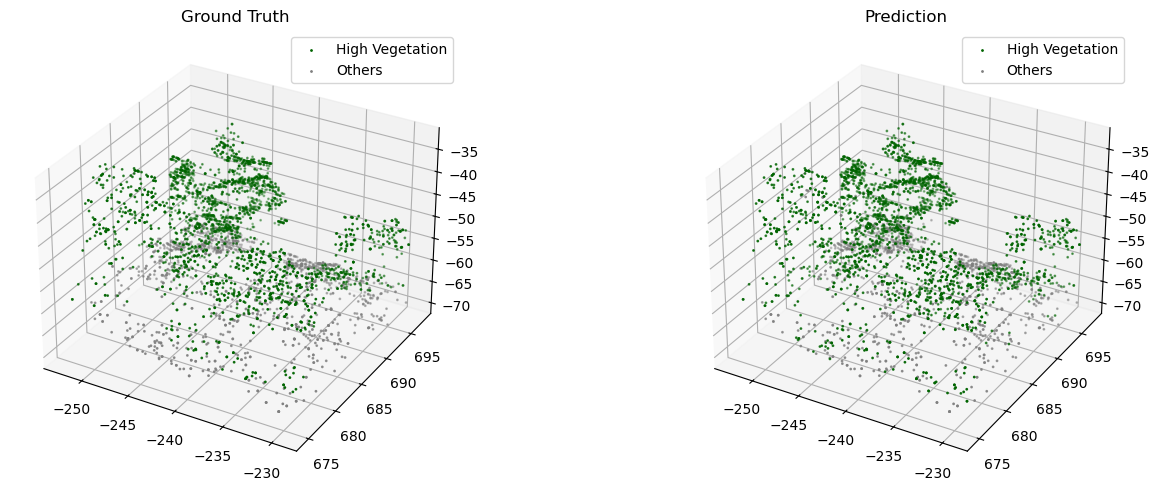

Saved visualization 1/5


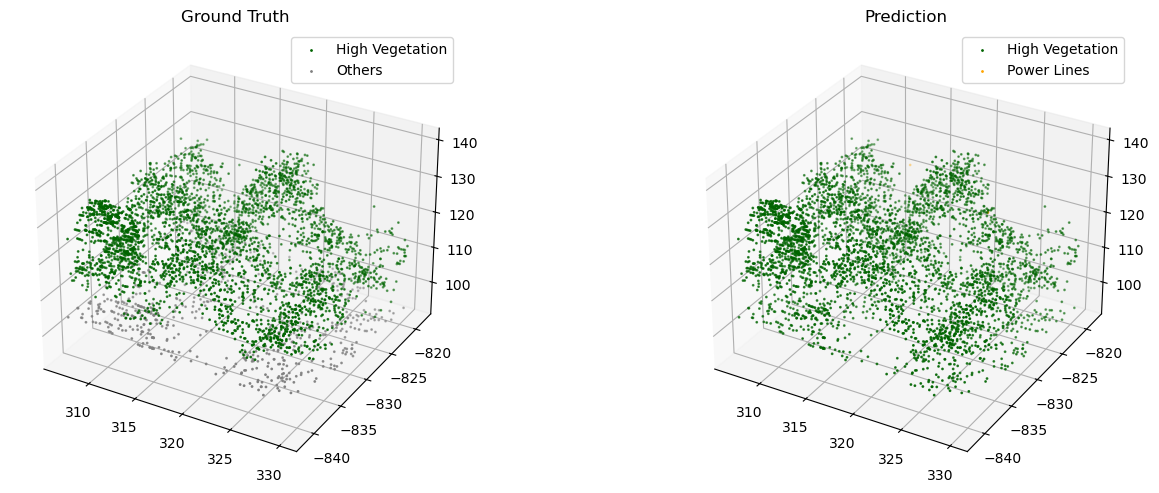

Saved visualization 2/5


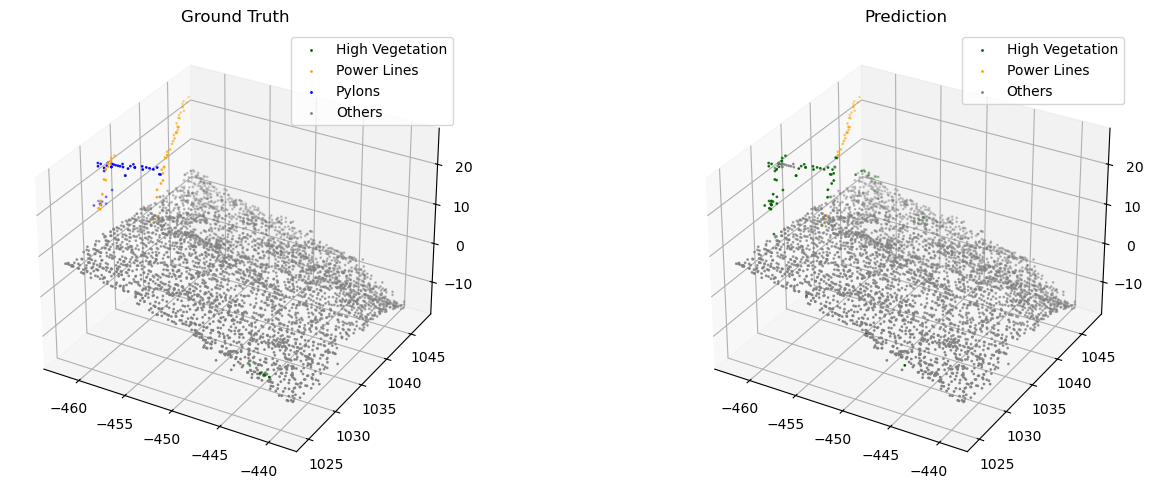

Saved visualization 3/5


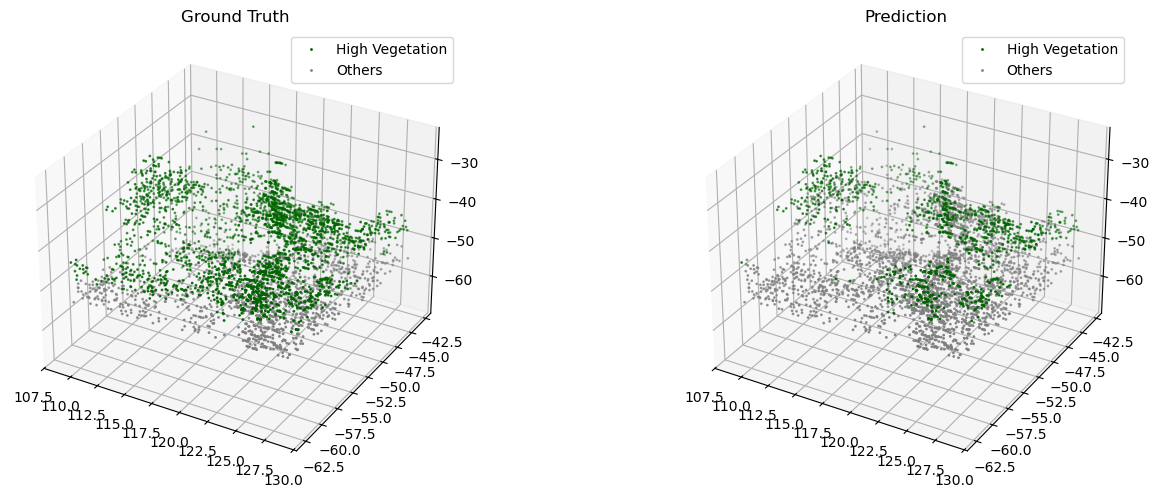

Saved visualization 4/5


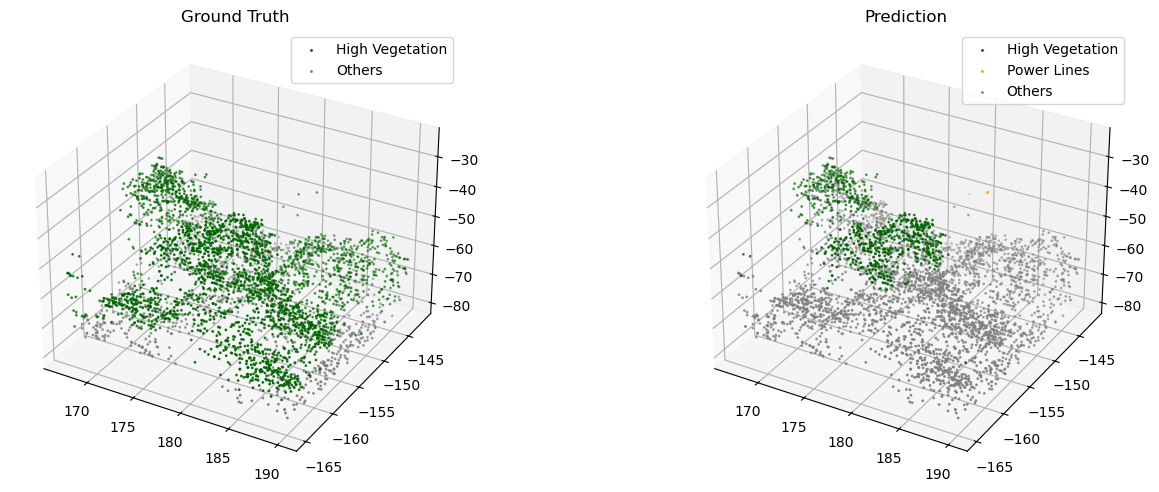

Saved visualization 5/5

Visualizations saved to predictions/


In [ ]:
def visualize_predictions(model, dataset, num_samples=None, output_dir=None):
    if num_samples is None:
        num_samples = NUM_VISUALIZATION_SAMPLES
    if output_dir is None:
        output_dir = PREDICTION_DIR
    
    Path(output_dir).mkdir(exist_ok=True)
    model.eval()
    
    for i in range(min(num_samples, len(dataset))):
        idx = np.random.randint(0, len(dataset))
        sample = dataset[idx]
        points = sample['points'].unsqueeze(0).to(model.device)
        labels = sample['labels'].numpy()
        
        with torch.no_grad():
            logits = model(points)
            pred = logits.argmax(dim=-1).cpu().numpy()[0]
        
        fig = plt.figure(figsize=(15, 5))
        points_np = sample['points'].numpy()
        
        ax1 = fig.add_subplot(121, projection='3d')
        for cls in range(NUM_CLASSES):
            mask = labels == cls
            if mask.sum() > 0:
                ax1.scatter(points_np[mask, 0], points_np[mask, 1], points_np[mask, 2], 
                           c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=1)
        ax1.set_title('Ground Truth')
        ax1.legend()
        
        ax2 = fig.add_subplot(122, projection='3d')
        for cls in range(NUM_CLASSES):
            mask = pred == cls
            if mask.sum() > 0:
                ax2.scatter(points_np[mask, 0], points_np[mask, 1], points_np[mask, 2], 
                           c=CLASS_COLORS[cls], label=CLASS_NAMES[cls], s=1)
        ax2.set_title('Prediction')
        ax2.legend()
        
        plt.tight_layout()
        plt.savefig(f'{output_dir}/sample_{i:03d}.png', dpi=VISUALIZATION_DPI)
        plt.show()
        print(f"Saved visualization {i+1}/{num_samples}")
    
    print(f"\nVisualizations saved to {output_dir}/")


test_dataset = PowerLineDataset(DATA_DIR, split='test', use_fps=False)
print("Generating visualizations...")
visualize_predictions(model, test_dataset)

## 13. Load Saved Model

In [ ]:
best_model_path = Path(CHECKPOINT_DIR) / 'pointtransformer-epoch=04-val_miou=0.421.ckpt'

if best_model_path.exists():
    print(f"Loading model from {best_model_path}...")
    loaded_model = PointTransformerLightning.load_from_checkpoint(str(best_model_path))
    loaded_model.eval()
    device, _, _ = get_device_info()
    loaded_model = loaded_model.to(device)
    print(f"Model loaded and moved to {device}")
else:
    print(f"Checkpoint not found at {best_model_path}")

Loading model from checkpoints/pointtransformer-epoch=04-val_miou=0.421.ckpt...
Using Apple Silicon MPS
Model loaded and moved to mps


## Summary

This notebook provides a complete pipeline for:
1. **Configuration** - All tunable parameters at the top
2. Loading LiDAR point cloud data
3. Training a Point Transformer V2 model
4. Evaluating with IoU metrics
5. Visualizing predictions

**To modify settings:** Edit the configuration in Section 1 and re-run all cells.